Кейс по классификации клиентов с помошью ML для определения плохих/хороших клиентов банка для выдачи кредитной карты

Задача

Сформулировать постановку задачу, которую хочется решать в рамках курса.
Критерии оценки:

1.1 Сформулирована бизнес-постановка задачи (например, реализовать спам/не спам детектор)

1.2 Сформулирована постановка ML-задачи (бинарная классификация)

1.3 Представлен набор данных, достаточный для решения поставленной задачи

Мне интересна тема финансов, поэтому выбрал датасет, связанный с выдачей кредитных карт.

ОТВЕТЫ

1.1 Бизнес постановка - нужно построить модель МО, которая будет автоматически по доступным данным  о клиенте определять можно ли выдавать карту кредитную клиенту или лучше не выдавать, потому что высокий риск просрочки и банк может потерять из-за этого деньги. С другой стороны, хорошие клиенты будут приносить деньги (сделаем поправку, что маленькая просрочка для банка это не плохо, если не более месяца - т.к банк может дополнительно заработать на комиссии)

1.2 Постановка задачи ML - нужно сделать бинарную классификацию, в которой хороший клиент это 0, а плохой клиент это 1. Хорошему выдаем карту, плохому нет. Для классификации у нас есть набор признаков о клиентах на входной выборке и мы будем получать эти же данные, когда будет приходить новый клиент. Плохого клиента определяем, как клиента с просрочкой больше или равной 2 месяцам (статусы есть в датасете)

1.3 Набор данных я нашел на kaggle. Источник: https://www.kaggle.com/datasets/rikdifos/credit-card-approval-prediction?resource=download . Датасет называется Credit Card Approval Prediction, он состоит из двух таблиц - первая это набор данных о клиентах по большей части соц.демография, вторая таблица - это данные по месяцам по каждому клиенту о факте или отсутствую просрочки. Надо будет потом эти таблицы соединить. Этих данных нам хватит, мы можем смержить таблицы, предварительно из второй сделав уникальные значенеия id и проставив статусы. Пропущенных значений нет - это удобно, не надо будет заполнять пропуски. Количество столбиков 18 у первой таблицы и 3 столбца у второй таблицы (id общий). Строк очень много - потом посмотрим какая длина, но данных точно достаточно для модели, весят файлы много




# 2 Выбрать и обосновать метрику для измерения качества.

В рамках данного пункта необходимо подобрать наиболее релевантную метрику или набор метрик для вашей задачи, написав краткое обоснование (1-2 предложения).

Критерии оценки:

2.1 Предложена метрика

2.2 Присутствует корректное обоснование (включая связь с бизнес-целью/продуктовыми метриками, анализ стоимости ошибок и особенности данных, например, дисбаланс)


ОТВЕТЫ

2.1 Выбираю метрику Recall (полнота по статусу, классу Плохой 1)

2.2 Ниже мы посмотрим данные, но уже перед разбором мы понимаем несколько вещей. Первое, скорее всего данные будут несбалансированные, должно быть намного больше людей, которые хорошие 0 без просрочки. Второе, нам не критично записать хорошего клиента в плохого, но вот записать плохого в хорошего - очень опасно, потеряем деньги выдав кредитку. Из этого следует, что нам лучше всего будет подходить метрика Recall (полнота по статусу, классу Плохой 1). Ранжировать не надо, пропустить хороших не критично, искать какой-то баланс между классами не нужно  - поэтому остальные метрики не будем рассматривать. По стоимости ошибки, нам дорого обойдутся ложно отрицательные предсказания (плохого клиента в хорошего определили) и будет потеря прибыли, но не критично при ложно положительном предсказании (когда хорошему клиенту не даои кредитку) - здесь мы дополнительно, на всякий случай будем смотреть метрику precision, чтобы понять не слишком ли мы часто отказыаем хорошим клиентам






# 3. Провести EDA на своих данных

В рамках данного пункта необходимо провести предварительный разведочный анализ своего набора данных.

Критерии оценки:

Рассмотрены базовые характеристики/статистики для набора данных - 3 балла
Реализованы наиболее релевантные визуализации - 5 баллов
По ходу работы присутствуют комментарии (вы, как эксперт в предметной области, можете проинтерпретировать полученные результаты анализа, визуализации, расcчитанные статистики, сделав выводы о том, каким образом лучше работать с набором данных в будущем, какие могут возникнуть проблемы, какую предобработку целесообразно сделать и тп). - 6 баллов


In [1]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Скачиваем датасет
path = kagglehub.dataset_download("rikdifos/credit-card-approval-prediction")
print("Путь:", path)
print("Файлы:", os.listdir(path))

Using Colab cache for faster access to the 'credit-card-approval-prediction' dataset.
Путь: /kaggle/input/credit-card-approval-prediction
Файлы: ['credit_record.csv', 'application_record.csv']


In [3]:
# Читаем оба файла
app = pd.read_csv(os.path.join(path, "application_record.csv"))
credit = pd.read_csv(os.path.join(path, "credit_record.csv"))

print("app:", app.shape)
print("credit:", credit.shape)

app: (438557, 18)
credit: (1048575, 3)


Комментирую:
мы загрузили датасеты - две таблицы. app - это заявки на кредитку, credit - это данные / временные ряды о просрочках

Мы видим, что в первой таблице 18 столбиков и 438 557 строк, во второй таблице 3 столбика и 1 048 575 строк (логично, что здесь больше строк, учитывая структуру данных по месяцам в каждой строке)

Можем считать, что выборка достаточно большая (посмотрим еще после соединения) и можно будет спокойно делать деление на обучающую и тестовую выборку, когда пойдем в обучение модели

Дальше посмотрим первые строки каждой таблицы и информацию общую о данных в них

In [4]:
app.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [5]:
app.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL       

Видим, что гендер задан категорией, будет здорово их перевести в бинарную числовую переменную 1/0. Аналогично с наличием машины и недвижимости - надо будет их перезадать в числовые. Видим, что много переменных категориальных дальше идет, есть числовые (причем одни небольшие по размаху про количество детей скорее всего и огромные - про количество дней от дня рождения - очень вероятно, что надо будет уменьшать размерность, может стандартизировать, а может дни перевести в годы). Несмотря на то, что в описании датасета я читал, что нет пропущенных данных - я вижу, что есть NaN в столбике OCCUPATION_TYPE (род деятельности) - надо будет посмотреть количество пропусков и насколько вообще мы можем использовать данный столбик в модели, потому что родов деятельности/ работ может быть очень много и без какой-то предварительной кластеризации использовать данную переменную будет очень тяжело

Статусы заданы категориальными данными. Надо проверить их количество и возможно перевести в числовые значения - создав по столбику на каждый тип для каждой категории

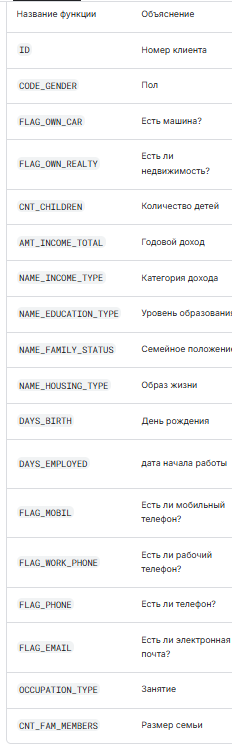

In [6]:
credit.head()

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [7]:
credit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 3 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   ID              1048575 non-null  int64 
 1   MONTHS_BALANCE  1048575 non-null  int64 
 2   STATUS          1048575 non-null  object
dtypes: int64(2), object(1)
memory usage: 24.0+ MB


Во втором наборе данных мы видим, что есть числовая переменная задающая месяц, в который оценивается просрочка. Есть переменная статус - которая описывает просрочку или ее отсутствие - эта переменная должна быть обработана, потому что есть числовые и нечисловые значения внутри

В целом, нам не нужны данные по месяцам, нам просто важен файт наличия просрочки равный или более двух месяцев, чтобы разметить данные. А id оставим потом уникальные только

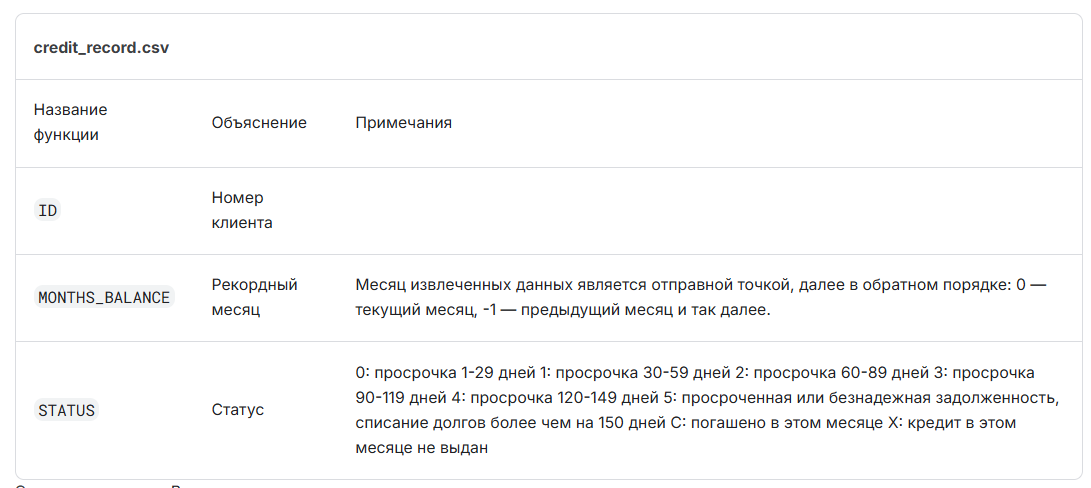

In [8]:
print("Пропуски в app:")
print(app.isna().sum()[app.isna().sum() > 0])  # показать только колонки с пропусками

Пропуски в app:
OCCUPATION_TYPE    134203
dtype: int64


Видим, что у нас много пропусков в роде деятельности, но зато только в нем. Примерно четверть всех данных или больше. Возможно мы просто не будем учитывать эту переменную или будет учитывать факт - наличие/отсутствие. Это может быть знак - почему клиент не оставил эти данные? Или мы не смогли эти данные собрать об этом клиенте? Отсутствие указанного рода деятельности выглядит подозрительно, если это не тех.ошибка при сборе данных


В credit нет пропусков, проверял. Посмотрим статусы все уникальные тогда

In [9]:
# Уникальные значения STATUS и сколько раз встречаются
print(credit["STATUS"].value_counts())

STATUS
C    442031
0    383120
X    209230
1     11090
5      1693
2       868
3       320
4       223
Name: count, dtype: int64


Видим, что уникальных значений статусов 8 шт. С, Х, 0, 1 берем за хорошие, будем кодировать как "0". А все оставльные статусы - это плохо, будет кодировать как "1"

Описание значений:

C — клиент закрыл кредит, не плохо

X — кредита в этом месяце не было —  не плохо

0 — небольшая просрочка (1–29 дней) — не плохо

1 — просрочка 30–59 дней — не плохо

2, 3, 4, 5 — большие просрочки более 59 дней - плохо

In [10]:
# Создаём бинарную переменную "плохой" для каждой строки
# True, если STATUS входит в набор {2, 3, 4, 5}
credit['is_bad_status'] = credit['STATUS'].isin(['2', '3', '4', '5'])

# Группируем по ID и берём "максимум" флага:
# если хотя бы раз True — клиент плохой
target = credit.groupby('ID')['is_bad_status'].max().astype(int).reset_index()
target.columns = ['ID', 'target']

print(target.head())
print("\nРаспределение target:")
print(target['target'].value_counts())
print("\nДоля плохих клиентов:", target['target'].mean().round(4))

        ID  target
0  5001711       0
1  5001712       0
2  5001713       0
3  5001714       0
4  5001715       0

Распределение target:
target
0    45318
1      667
Name: count, dtype: int64

Доля плохих клиентов: 0.0145


Сделали новую переменную по статусу и сгруппировали все в дата фрейм target. Получили уникальные значения id и разметку - плохой 1 / хороший 0 таргет по наличию просрочек больших в истории клиента

Выводим долю "плохих" клиентов - это 1.45 %. Мы подтвердили, что у нас сильный дисбаланс в данных. Поэтому метрику правильно брали и в модели будет потом учитывать

Теперь можно мержить таблицы

In [11]:
# объединение по id
df = app.merge(target, on='ID', how='inner')

print("Форма после merge:", df.shape)
print("\nПропуски в target:", df['target'].isna().sum())
df.head()

Форма после merge: (36457, 19)

Пропуски в target: 0


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,target
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0,0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,0


Взяли только тех клиентов, кто есть и в app, и в target - сразу потеряли строки. Получается были id, для которые не было данных в какой-то из таблиц (скорее всего во второй). Осталось 36457 строк, все еще хорошо, но уже намного меньше, чем исходные данные. Поэтому посмотрим еще раз долю клиентов плохих

In [12]:
print("Доля плохих клиентов в объединенном датасете:", df['target'].mean().round(4))

Доля плохих клиентов в объединенном датасете: 0.0169


1.69 % "плохих" клиентов - получается дисбаланс все еще есть, но это ожидаемо

Переходим к общей статистике по объединенному датасету

In [13]:
df.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,target
count,3.645700e+04,36457.000000,3.645700e+04,36457.000000,36457.000000,36457.0,36457.000000,36457.000000,36457.000000,36457.000000,36457.000000
mean,5.078227e+06,0.430315,1.866857e+05,-15975.173382,59262.935568,1.0,0.225526,0.294813,0.089722,2.198453,0.016897
std,4.187524e+04,0.742367,1.017892e+05,4200.549944,137651.334859,0.0,0.417934,0.455965,0.285787,0.911686,0.128886
min,5.008804e+06,0.000000,2.700000e+04,-25152.000000,-15713.000000,1.0,0.000000,0.000000,0.000000,1.000000,0.000000
25%,5.042028e+06,0.000000,1.215000e+05,-19438.000000,-3153.000000,1.0,0.000000,0.000000,0.000000,2.000000,0.000000
50%,5.074614e+06,0.000000,1.575000e+05,-15563.000000,-1552.000000,1.0,0.000000,0.000000,0.000000,2.000000,0.000000
75%,5.115396e+06,1.000000,2.250000e+05,-12462.000000,-408.000000,1.0,0.000000,1.000000,0.000000,3.000000,0.000000
max,5.150487e+06,19.000000,1.575000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000,1.000000


In [14]:
#В нормальный вид привожу, без умножений на степени
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
df.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,target
count,"36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00"
mean,"5,078,227.00",0.43,"186,685.74","-15,975.17","59,262.94",1.00,0.23,0.29,0.09,2.20,0.02
std,"41,875.24",0.74,"101,789.23","4,200.55","137,651.33",0.00,0.42,0.46,0.29,0.91,0.13
min,"5,008,804.00",0.00,"27,000.00","-25,152.00","-15,713.00",1.00,0.00,0.00,0.00,1.00,0.00
25%,"5,042,028.00",0.00,"121,500.00","-19,438.00","-3,153.00",1.00,0.00,0.00,0.00,2.00,0.00
50%,"5,074,614.00",0.00,"157,500.00","-15,563.00","-1,552.00",1.00,0.00,0.00,0.00,2.00,0.00
75%,"5,115,396.00",1.00,"225,000.00","-12,462.00",-408.00,1.00,0.00,1.00,0.00,3.00,0.00
max,"5,150,487.00",19.00,"1,575,000.00","-7,489.00","365,243.00",1.00,1.00,1.00,1.00,20.00,1.00


По первичному просмотру несколько моментов:

1) ID мы не смотрим статистику
2) Количество детей - интересно, что максимум это 19. Возможно это ошибка или выброс, а может действительно такой пользователь есть. Но 75% пользователей имеют до 1 ребенка, 50% пользователей без детей, в среднем вообще 0.4 ребенка у клиентов. Дети могут влиять на расходы пользователя и на нуждаемость в кредитке
3) Разброс по доходу довольно большой, тут мы будем ожидать правостороннее распределение (посмотрим дальше). При этом тут надо изучить будет, что считать хорошим доходом, а что нет. Предполагаем заранее, что чем выше доход, тем меньше вероятность проблем с платежами у клиента. Возможны выбросы и возможно надо будет уменьшать размерность, стандартизировать
4) Дни рождения переведем потом в годы (сейчас разброс от 20 лет до 68 лет)  и стаж работы на последнем месте тоже. Тут есть подозрение, что безработные маркируются положительным числом, но максимум слишком большой - его надо проверить, это точно не настоящее количество дней поиска работы безработным. Сделаем классификацию, безработный (0) и есть работа (1)
5) Наличие мобильного телефона - у всех есть, бессмысленно в модель добавлять. Рабочий телефон есть у 23% пользователей, пока не понятно как это описывает пользователя, но посмотрим. Наличие телефона у 0.46 есть, емейл у 9%. В целом пока непонятно, как это можно использовать. Тут может быть это у банка есть или нет информации о пользователе
6) Размер семьи в среднем составляет 2.2 человека. По идее - чем больше размер семьи тем больше расходов, НО если это не дети, а взрослые, то это значит больше людей, которые могут помочь закрыть кредитку. Очень полезные фактор, особенно отделять одиночек, одиночек с детьми или большие семьи. Нужен доп.столбец с разницей между размером семьи и количеством детей, чтобы количество взрослых понимать в семье
7) Таргет на 1 - плохой пользователь мы уже описывали, меньше 2%, сильный дисбаланс

In [15]:
#Возраст посмотрел разброс
25152/365
7489/365

20.517808219178082

In [16]:
# Сколько строк с положительным DAYS_EMPLOYED
print("Положительных значений:", (df['DAYS_EMPLOYED'] > 0).sum())

# Сколько всего строк
print("Всего строк:", len(df))

# Сколько из них именно 365243 (код "безработный")
print("Равно 365243:", (df['DAYS_EMPLOYED'] == 365243).sum())

# Какие вообще положительные значения бывают
print("Уникальные положительные значения:")
print(df[df['DAYS_EMPLOYED'] > 0]['DAYS_EMPLOYED'].unique())

Положительных значений: 6135
Всего строк: 36457
Равно 365243: 6135
Уникальные положительные значения:
[365243]


Мы видим, что все безработные маркируются огромным положительным числом в стаже текущей работы, который у нас вообще то отрицательно закодирован

Просто делаем разбивку на есть работа 1 и безработный 0. И добавляем столбики о которых писал в прошлом блоке

In [17]:
# 1. Возраст в годах
# DAYS_BIRTH хранит "сколько дней назад родился" в виде отрицательного числа.
# Ставим минус, чтобы получить положительные дни, и делим на 365.
df['age_years'] = -df['DAYS_BIRTH'] / 365

# 2. Бинарный флаг "есть работа": 1 = работает, 0 = безработный
# По логике датасета:
#   - отрицательное DAYS_EMPLOYED → работает
#   - положительное (равно 365243) → безработный
df['is_employed'] = (df['DAYS_EMPLOYED'] < 0).astype(int)

# 3. Сколько в семье людей, кроме детей (= "взрослые")
df['adults_in_family'] = df['CNT_FAM_MEMBERS'] - df['CNT_CHILDREN']

In [18]:
#В нормальный вид привожу, без умножений на степени
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
df.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,target,age_years,is_employed,adults_in_family
count,"36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00","36,457.00"
mean,"5,078,227.00",0.43,"186,685.74","-15,975.17","59,262.94",1.00,0.23,0.29,0.09,2.20,0.02,43.77,0.83,1.77
std,"41,875.24",0.74,"101,789.23","4,200.55","137,651.33",0.00,0.42,0.46,0.29,0.91,0.13,11.51,0.37,0.42
min,"5,008,804.00",0.00,"27,000.00","-25,152.00","-15,713.00",1.00,0.00,0.00,0.00,1.00,0.00,20.52,0.00,-1.00
25%,"5,042,028.00",0.00,"121,500.00","-19,438.00","-3,153.00",1.00,0.00,0.00,0.00,2.00,0.00,34.14,1.00,2.00
50%,"5,074,614.00",0.00,"157,500.00","-15,563.00","-1,552.00",1.00,0.00,0.00,0.00,2.00,0.00,42.64,1.00,2.00
75%,"5,115,396.00",1.00,"225,000.00","-12,462.00",-408.00,1.00,0.00,1.00,0.00,3.00,0.00,53.25,1.00,2.00
max,"5,150,487.00",19.00,"1,575,000.00","-7,489.00","365,243.00",1.00,1.00,1.00,1.00,20.00,1.00,68.91,1.00,2.00


Комментарий по новым трем столбцам
1) Возраст в среднем 43,77 лет, медиана 42.64
2) С работой людей около 83%, соответственно 17% безработных
3) Очень странно. что взрослых в семье есть одно отрицательное значение, видимо есть строка, где 2 ребенка и нет взрослого. очень странно надо проверять. Но в среднем большинство пользователей находятся в паре - 1.77 взрослых в семье в среднем

In [19]:
# Все строки, где взрослых ≤ 0
anomalies = df[df['adults_in_family'] <= 0]

print("Всего аномальных строк:", len(anomalies))
anomalies[['ID',"age_years", 'CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'adults_in_family']]

Всего аномальных строк: 8


,ID,age_years,CNT_CHILDREN,CNT_FAM_MEMBERS,adults_in_family
36121,5010869,49.79,1,1.00,0.00
36138,5023641,40.48,2,1.00,-1.00
36187,5045457,39.59,2,1.00,-1.00
36227,5053148,33.26,1,1.00,0.00
36233,5054068,45.00,1,1.00,0.00
36279,5089953,34.95,1,1.00,0.00
36425,5142973,29.19,1,1.00,0.00
36436,5146078,34.86,1,1.00,0.00


Строки, где количество взрослых отрицательное или нулевое при высоком возрасте - это явно выбросы, мы их удалим. Можно было бы конечно пересчитать их, но лучше просто удалим, данных много. Выбросы сейчас чистить не надо в дз, но дальше перед построением модели почистим все

# Визуализация

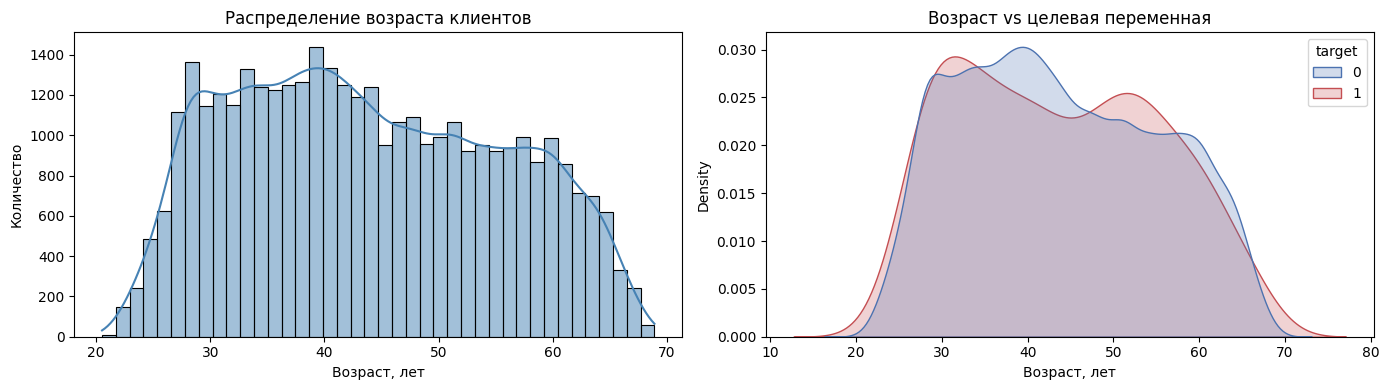

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Слева — общее распределение возраста
sns.histplot(df['age_years'], bins=40, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Распределение возраста клиентов')
axes[0].set_xlabel('Возраст, лет')
axes[0].set_ylabel('Количество')

# Справа — возраст в разрезе target
sns.kdeplot(data=df, x='age_years', hue='target', fill=True,
            common_norm=False, palette=['#4C72B0', '#C44E52'], ax=axes[1])
axes[1].set_title('Возраст vs целевая переменная')
axes[1].set_xlabel('Возраст, лет')

plt.tight_layout()
plt.show()

По распределению по возрасту мы видим, что у нас растет количество пользователей на промежутке от 20 до 28 лет, далее стабильное количество до 45 и небольшое снижение. Сильное снижение после 60 лет

Если мы посмотрим правый график с разбитием по возрасту и целевой переменной, то мы увидим не сильные различия, но Хороших клиентов больше в возрасте примерно 40 лет, а "плохих" клиентов в возрасте от 20 до 30 и от 50 до 60 лет - это мы логично объясним тем, что это периоды когда либо нет нормальной работы, либо уже уход на пенсию

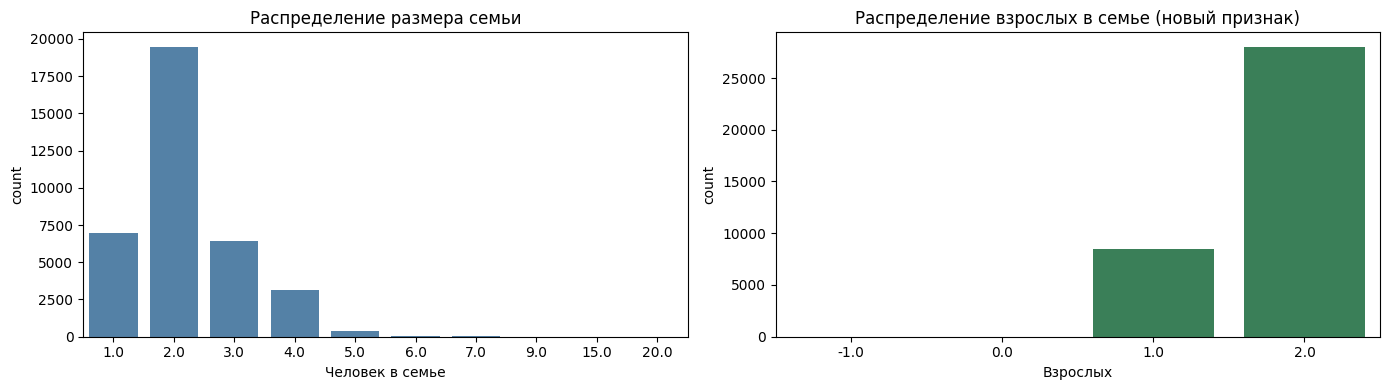

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Слева — размер семьи
sns.countplot(data=df, x='CNT_FAM_MEMBERS', color='steelblue', ax=axes[0])
axes[0].set_title('Распределение размера семьи')
axes[0].set_xlabel('Человек в семье')

# Справа — "взрослые" из нового признака
sns.countplot(data=df, x='adults_in_family', color='seagreen', ax=axes[1])
axes[1].set_title('Распределение взрослых в семье (новый признак)')
axes[1].set_xlabel('Взрослых')

plt.tight_layout()
plt.show()


По размеру семьи мы видим, что мода - это 2 человека и эта группа сильно больше по количеству чем остальных. 1,3,4 тоже достаточно количество, а вот 5 и далее - уже сильно меньше таких

По количеству взрослых - большинство вдвоем, но около 10 000 клиентов одни

/tmp/ipykernel_4501/1208246557.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=bad_rate.values, y=bad_rate.index, ax=axes[i], palette='Reds_r')
/tmp/ipykernel_4501/1208246557.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=bad_rate.values, y=bad_rate.index, ax=axes[i], palette='Reds_r')
/tmp/ipykernel_4501/1208246557.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=bad_rate.values, y=bad_rate.index, ax=axes[i], palette='Reds_r')
/tmp/ipykernel_4501/1208246557.py:10: FutureWarning: 

Passing `palette` without assigning `hu

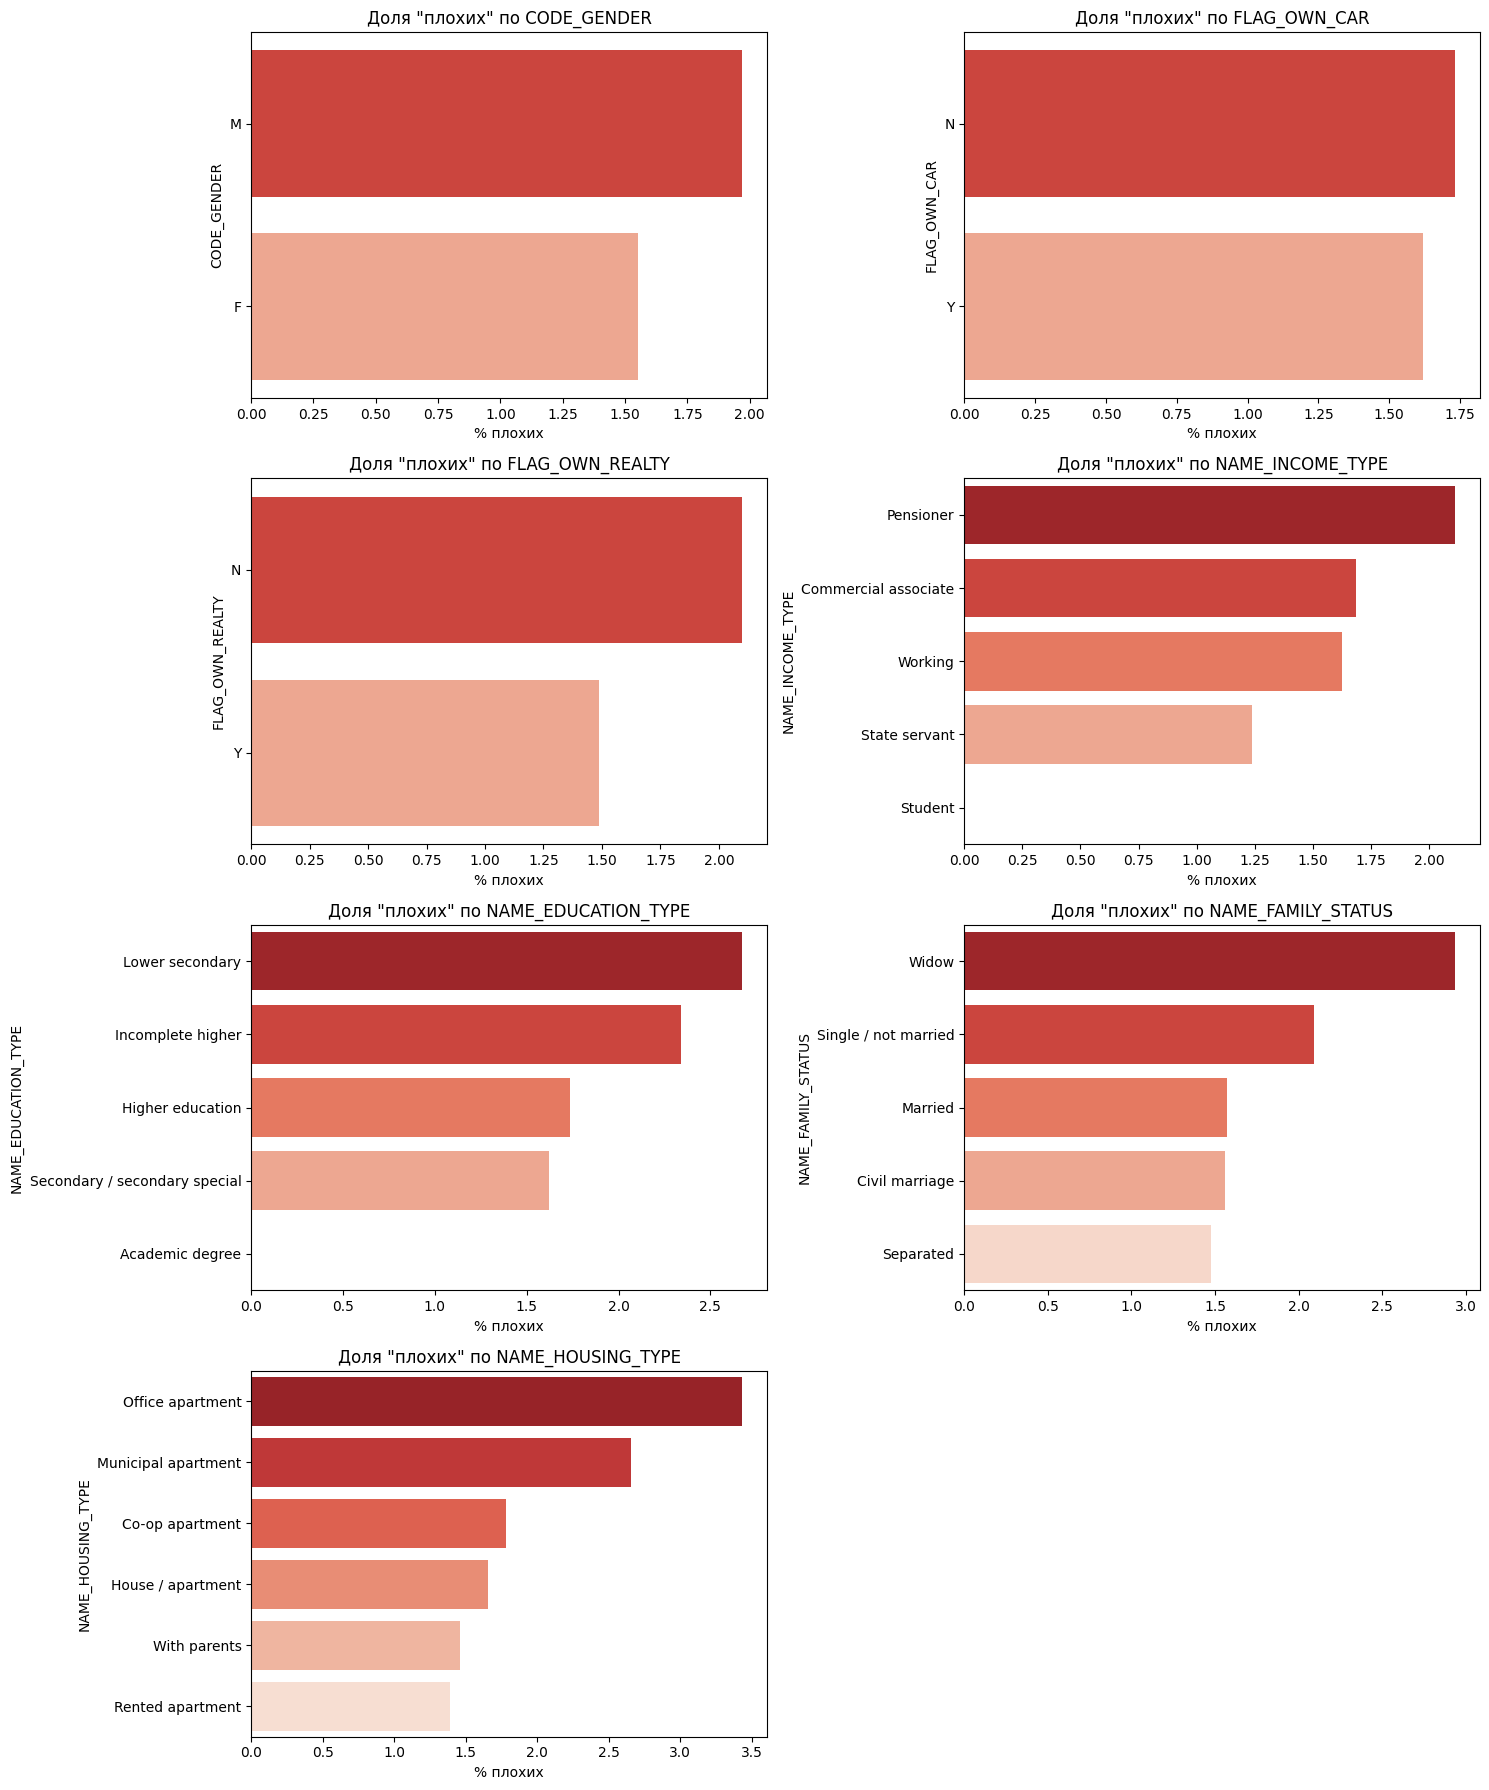

In [22]:
categorical_cols = ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
                    'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE',
                    'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE']

fig, axes = plt.subplots(4, 2, figsize=(15, 18))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    bad_rate = df.groupby(col)['target'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=bad_rate.values, y=bad_rate.index, ax=axes[i], palette='Reds_r')
    axes[i].set_title(f'Доля "плохих" по {col}')
    axes[i].set_xlabel('% плохих')

# Скрываем последний пустой график (7 признаков на 8 ячеек)
axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

По категориальным переменным мы видим, что доля "плохих" клиентов среди мужчин чуть больше, чуть больше у тех кто без машины и недвижимости. Больше среди пенсионеров, тех у кого низкое образование, вдов и одиночек, тех кто живет в офисных апартаментах

Здесь я понял, что надо перезадать некоторые категориальные переменные и перевести их в числовые (пол, наличие машины и недвижимости)

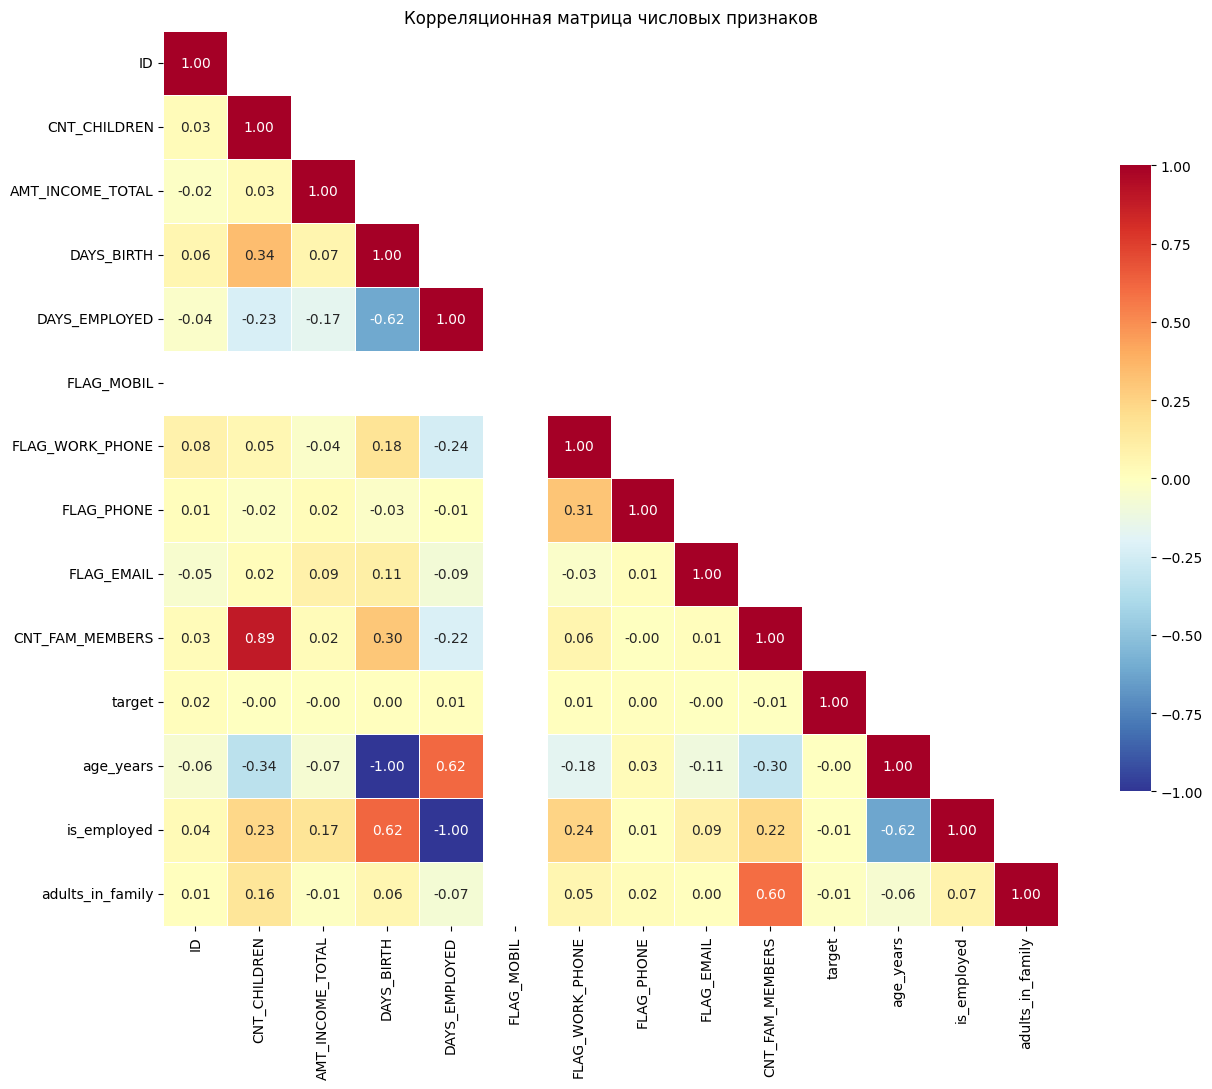

In [23]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # верхний треугольник скрываем
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlBu_r', center=0, square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.7})
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

По корреляционной матрице нет каких-то сильных корреляций, все логично и в норме

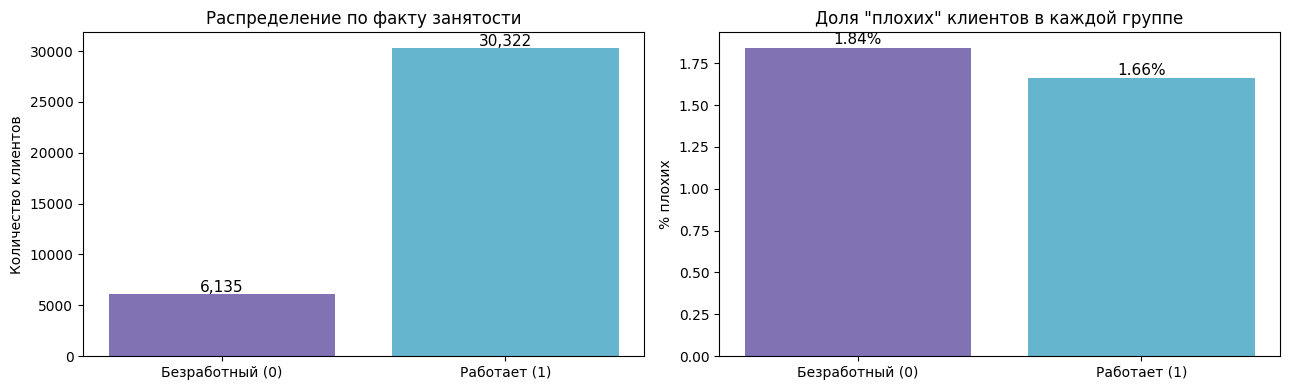

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Слева — сколько работает / не работает
emp_counts = df['is_employed'].value_counts().sort_index()
axes[0].bar(['Безработный (0)', 'Работает (1)'], emp_counts.values,
            color=['#8172B3', '#64B5CD'])
axes[0].set_title('Распределение по факту занятости')
axes[0].set_ylabel('Количество клиентов')
for i, v in enumerate(emp_counts.values):
    axes[0].text(i, v + 200, f'{v:,}', ha='center', fontsize=11)

# Справа — доля "плохих" среди работающих и безработных
bad_rate = df.groupby('is_employed')['target'].mean() * 100
axes[1].bar(['Безработный (0)', 'Работает (1)'], bad_rate.values,
            color=['#8172B3', '#64B5CD'])
axes[1].set_title('Доля "плохих" клиентов в каждой группе')
axes[1].set_ylabel('% плохих')
for i, v in enumerate(bad_rate.values):
    axes[1].text(i, v + 0.02, f'{v:.2f}%', ha='center', fontsize=11)

plt.tight_layout()
plt.show()

Безработных сильно меньше, но доля среди них "плохих" выше, хотя кажется что не сильно


В итоге данные у нас есть, их много, есть переменные которые можно использовать потом в модели. в завершение в последнем блоке сделаю перевод переменных некоторых в бинарные, чтобы к следующему дз был готовый датафрейм

In [25]:
# 1. Создаём копию датасета
df2 = df.copy()

# 2. Пол: M → 1, F → 0
df2['CODE_GENDER'] = df2['CODE_GENDER'].map({'M': 1, 'F': 0})

# 3. Наличие машины: Y → 1, N → 0
df2['FLAG_OWN_CAR'] = df2['FLAG_OWN_CAR'].map({'Y': 1, 'N': 0})

# 4. Наличие недвижимости: Y → 1, N → 0
df2['FLAG_OWN_REALTY'] = df2['FLAG_OWN_REALTY'].map({'Y': 1, 'N': 0})

# 5. Проверяем результат
print("Типы после замены:")
print(df2[['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']].dtypes)
print("\nПример данных:")
print(df2[['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']].head())
print("\nУникальные значения:")
print("CODE_GENDER:", df2['CODE_GENDER'].unique())
print("FLAG_OWN_CAR:", df2['FLAG_OWN_CAR'].unique())
print("FLAG_OWN_REALTY:", df2['FLAG_OWN_REALTY'].unique())

Типы после замены:
CODE_GENDER        int64
FLAG_OWN_CAR       int64
FLAG_OWN_REALTY    int64
dtype: object

Пример данных:
   CODE_GENDER  FLAG_OWN_CAR  FLAG_OWN_REALTY
0            1             1                1
1            1             1                1
2            1             1                1
3            0             0                1
4            0             0                1

Уникальные значения:
CODE_GENDER: [1 0]
FLAG_OWN_CAR: [1 0]
FLAG_OWN_REALTY: [1 0]


еще степень образования переведем в числовые по возрастанию. Судя по визуализации нам пригодится этот признак и мы его по возрастанию зададим числовой переменной

In [26]:
# Словарь: уровень образования → число (чем выше образование, тем больше число)
education_map = {
    'Lower secondary'            : 0,
    'Secondary / secondary special': 1,
    'Incomplete higher'          : 2,
    'Higher education'           : 3,
    'Academic degree'            : 4
}

df2['NAME_EDUCATION_TYPE'] = df2['NAME_EDUCATION_TYPE'].map(education_map)

# Проверяем
print(df2['NAME_EDUCATION_TYPE'].value_counts().sort_index())
print("\nПропуски:", df2['NAME_EDUCATION_TYPE'].isna().sum())

NAME_EDUCATION_TYPE
0      374
1    24777
2     1410
3     9864
4       32
Name: count, dtype: int64

Пропуски: 0


In [27]:
df2

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,...,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,target,age_years,is_employed,adults_in_family
0,5008804,1,1,1,0,"427,500.00",Working,3,Civil marriage,Rented apartment,...,1,1,0,0,NaN,2.00,0,32.89,1,2.00
1,5008805,1,1,1,0,"427,500.00",Working,3,Civil marriage,Rented apartment,...,1,1,0,0,NaN,2.00,0,32.89,1,2.00
2,5008806,1,1,1,0,"112,500.00",Working,1,Married,House / apartment,...,1,0,0,0,Security staff,2.00,0,58.83,1,2.00
3,5008808,0,0,1,0,"270,000.00",Commercial associate,1,Single / not married,House / apartment,...,1,0,1,1,Sales staff,1.00,0,52.36,1,1.00
4,5008809,0,0,1,0,"270,000.00",Commercial associate,1,Single / not married,House / apartment,...,1,0,1,1,Sales staff,1.00,0,52.36,1,1.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36452,5149828,1,1,1,0,"315,000.00",Working,1,Married,House / apartment,...,1,0,0,0,Managers,2.00,1,47.53,1,2.00
36453,5149834,0,0,1,0,"157,500.00",Commercial associate,3,Married,House / apartment,...,1,0,1,1,Medicine staff,2.00,1,33.94,1,2.00
36454,5149838,0,0,1,0,"157,500.00",Pensioner,3,Married,House / apartment,...,1,0,1,1,Medicine staff,2.00,1,33.94,1,2.00
36455,5150049,0,0,1,0,"283,500.00",Working,1,Married,House / apartment,...,1,0,0,0,Sales staff,2.00,1,49.20,1,2.00


Метрики выбрали, данные изучили, визуализцию сделали, полезные переменные заранее создали и перевели в числовые. Дальше можно будет уже модель строить

# ПОСТРОЕНИЕ МОДЕЛЕЙ

Задание 2

Построить и оценить качество бейзлайна
В рамках данного пункта необходимо выбрать и обучить бейзлайн-модели, а также измерить их качество.

In [28]:
# Удаляем 8 аномальных строк, где количество взрослых <= 0
print(f"Размер df2 до очистки: {df2.shape}")
df_final = df2[df2['adults_in_family'] > 0].copy()

# Удаляем колонку ID — она не нужна для обучения
df_final = df_final.drop(columns=['ID'])

print(f"Размер df_final после очистки: {df_final.shape}")
print(f"Проверка: остались ли аномалии {(df_final['adults_in_family'] <= 0).sum()}")

Размер df2 до очистки: (36457, 22)
Размер df_final после очистки: (36449, 21)
Проверка: остались ли аномалии 0


1. Произведено разбиение датасета на тренировочную/тестовую выборки
2. Произведено измерение качества константного предсказания (например, наиболее частотный класс для классификации, среднее/медиана для регрессии)


In [29]:
from sklearn.model_selection import train_test_split

# X — признаки, y — то, что предсказываем
X = df_final.drop(columns=['target'])
y = df_final['target']

# 80% — обучение, 20% — тест
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Доля 'плохих' в train: {y_train.mean():.4f}")
print(f"Доля 'плохих' в test:  {y_test.mean():.4f}")

Train: (29159, 20), Test: (7290, 20)
Доля 'плохих' в train: 0.0167
Доля 'плохих' в test:  0.0167


Мы получили train из 29 159 строк и test из 7 290 строк. Делил 80% на 20%, чтобы чуть больше попало в выборке обучающую (обычно 70/30). Доля "плохих" в обеих выборках одинаковая 0.0169 (специально фиксировали), значит, мы можем брать для работы такие выборки, в обоих одинаковая доля "плохих" - нам это важно при дисбалансе выборок

Дополняю дз1 - добавляем цену ошибки и стоимость для бизнеса

Бизнес-логика цены ошибки и пороги метрик

Исходы
TP (True Positive)	Плохого клиента отклонили	+ L_bad (сэкономили на потенциальном убытке)

FP (False Positive)	Хорошего клиента отклонили	− P_good (потеряли прибыль)

FN (False Negative)	Плохого клиента одобрили	− L_bad (понесли убыток)

TN (True Negative)	Хорошего клиента одобрили	+ P_good (получили прибыль)

В ОПИСАНИИ ДАТА СЕТА НЕТ НАЗВАНИЯ ВАЛЮТЫ. СКОРЕЕ ВСЕГО ОПИСЫВАЕТСЯ ДОХОД КЛИЕНТА В ГОД И НЕ В РУБЛЯХ, НО Т.К МЫ НЕ ЗНАЕМ ТОЧНО ВАЛЮТУ, ТО Я БЕРУ ДАЛЬШЕ РУБЛИ ДЛЯ РАСЧЕТА ПОЛУЧЕННОЙ ВЫГОДЫ ОТ РАЗНЫХ МОДЕЛЕЙ - ЭТО НУЖНО ТОЛЬКО ДЛЯ СРАВНЕНИЯ МОДЕЛЕЙ

Задаю типовые для рынка кредитных карт значения (обоснование ниже):
P_good = 10 000 ₽ — среднегодовая прибыль с одного клиента
L_bad = 60 000 ₽ — средний убыток при дефолте

Соотношение L_bad / P_good = 6:1. Это типичный порядок для потребительского кредитования: потерять на дефолтнике в 5–10 раз больнее, чем не заработать на хорошем.

Отсюда — экономический порог Precision (точка безубыточности):

Каждый раз, когда модель говорит "плохой", мы либо экономим L_bad (если клиент реально плохой — вероятность = Precision), либо теряем P_good (если клиент реально хороший — вероятность = 1 − Precision). Чтобы стратегия "отклонять по модели" имела смысл:

Экономический порог Recall: задаётся бизнес-требованием к риск-аппетиту. Банк готов пропустить не более половины дефолтников: Recall_min = 0.50.

Дополнительно считаем денежный uplift от baseline (без модели, одобряем всех):

Если Uplift > 0 — модель приносит банку больше денег, чем baseline. Это главный бизнес-критерий.

In [30]:
# ===== БИЗНЕС-ПАРАМЕТРЫ (в рублях) =====
# Типовые значения для рынка кредитных карт РФ.
# В реальном проекте задаются финансовым департаментом банка.
P_GOOD = 10_000     # прибыль с одного хорошего клиента за год
L_BAD  = 60_000     # убыток с одного дефолтника

# Соотношение "убыток / прибыль"
print(f"Соотношение L_bad / P_good = {L_BAD / P_GOOD:.1f}:1")

# ===== ЭКОНОМИЧЕСКИЕ ПОРОГИ МЕТРИК =====
# Минимальный Precision (точка безубыточности модели)
PRECISION_MIN = P_GOOD / (P_GOOD + L_BAD)

# Минимальный Recall (риск-аппетит банка: пропустить не более 50% плохих)
RECALL_MIN = 0.50

print(f"\n=== Экономические пороги ===")
print(f"Precision_min = {PRECISION_MIN:.4f}  (ниже — модель убыточна)")
print(f"Recall_min    = {RECALL_MIN:.2f}    (ниже — банк пропускает >50% дефолтников)")


# ===== ФУНКЦИЯ РАСЧЁТА ДЕНЕЖНОГО UPLIFT =====
def business_uplift(y_true, y_pred, p_good=P_GOOD, l_bad=L_BAD):
    """
    Считает денежный выигрыш от применения модели по сравнению с baseline
    (baseline = одобряем всех, без модели).

    Uplift = TP * L_bad - FP * P_good
    Положительное значение => модель зарабатывает больше, чем baseline.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())

    saved_losses = tp * l_bad         # избежали убытков на пойманных плохих
    lost_profit  = fp * p_good        # потеряли прибыль на ошибочно отклонённых
    missed_loss  = fn * l_bad         # понесли убыток на пропущенных плохих

    uplift = saved_losses - lost_profit
    return {
        'TP': tp, 'FP': fp, 'FN': fn,
        'saved_losses_rub': saved_losses,
        'lost_profit_rub':  lost_profit,
        'missed_loss_rub':  missed_loss,
        'uplift_rub':       uplift,
    }


# Демонстрация работы на baseline (Dummy — все одобрены)
# Прогоним, чтобы убедиться, что baseline даёт uplift = 0
baseline_demo = business_uplift(y_test, np.zeros_like(y_test))
print("\n=== Uplift для baseline (одобряем всех) ===")
print(f"Uplift: {baseline_demo['uplift_rub']:,} руб.  (должен быть 0)")

Соотношение L_bad / P_good = 6.0:1

=== Экономические пороги ===
Precision_min = 0.1429  (ниже — модель убыточна)
Recall_min    = 0.50    (ниже — банк пропускает >50% дефолтников)

=== Uplift для baseline (одобряем всех) ===
Uplift: 0 руб.  (должен быть 0)


1.2 Произведено измерение качества константного предсказания

In [31]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import recall_score, precision_score

dummy_pipeline = Pipeline([
    ('classifier', DummyClassifier(strategy='most_frequent', random_state=42)),
])

dummy_pipeline.fit(X_train, y_train)
y_pred_dummy = dummy_pipeline.predict(X_test)

# Считаем только 2 метрики + бизнес-эффект
dummy_recall = recall_score(y_test, y_pred_dummy)
dummy_precision = precision_score(y_test, y_pred_dummy, zero_division=0)
dummy_uplift = business_uplift(y_test, y_pred_dummy)

print("=== DummyClassifier (baseline) ===")
print(f"Recall:    {dummy_recall:.4f}")
print(f"Precision: {dummy_precision:.4f}")
print(f"Uplift:    {dummy_uplift['uplift_rub']:,} руб.")
print(f"\nПроходит пороги?")
print(f"  Recall ≥ {RECALL_MIN}:     {dummy_recall >= RECALL_MIN}")
print(f"  Precision ≥ {PRECISION_MIN:.3f}: {dummy_precision >= PRECISION_MIN}")
print(f"  Uplift > 0:            {dummy_uplift['uplift_rub'] > 0}")


=== DummyClassifier (baseline) ===
Recall:    0.0000
Precision: 0.0000
Uplift:    0 руб.

Проходит пороги?
  Recall ≥ 0.5:     False
  Precision ≥ 0.143: False
  Uplift > 0:            False


DummyClassifier: Recall = 0.0, Precision = 0.0, Uplift = 0 руб. Ниже всех порогов. Это нижняя граница — любая осмысленная модель должна ее превзойти. По сути модель просто всех определяет как "Хороших"

1.3 Бейзлайновая модель из простого семейства обучена, учтены особенности предобработки


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

categorical_features = [
    'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS',
    'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE',
]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
])

# Бейзлайн 1: LogisticRegression
logreg_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced', random_state=42, max_iter=1000,
    )),
])
logreg_pipeline.fit(X_train, y_train)
y_pred_logreg = logreg_pipeline.predict(X_test)

# Бейзлайн 2: DecisionTree
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        class_weight='balanced', random_state=42, max_depth=5,
    )),
])
tree_pipeline.fit(X_train, y_train)
y_pred_tree = tree_pipeline.predict(X_test)

Я выбрал логистическую регрессию и дерево решений как простые модели. В логистической можно будет задавать пороги и иметь числовое значение, а в дереве решений будет больше возможность интерпретации хотя она скорее будет слабее. Обе модели обучены с учётом дисбаланса и предобработки. Готовы к оценке

1.4 Измерение качества на отложенной выборке с использованием ранее выбранной метрики


In [33]:
import pandas as pd

def build_results_row(name, y_true, y_pred):
    """Собирает строку метрик + бизнес-эффект для одной модели."""
    r = recall_score(y_true, y_pred)
    p = precision_score(y_true, y_pred, zero_division=0)
    u = business_uplift(y_true, y_pred)
    return {
        'Модель':          name,
        'Recall':          round(r, 4),
        'Precision':       round(p, 4),
        'Uplift (тыс. руб.)': round(u['uplift_rub'] / 1000, 1),
        'R ≥ 0.50':        '✅' if r >= RECALL_MIN else '❌',
        'P ≥ 0.143':       '✅' if p >= PRECISION_MIN else '❌',
        'Uplift > 0':      '✅' if u['uplift_rub'] > 0 else '❌',
    }

baseline_results = pd.DataFrame([
    build_results_row('Dummy',            y_test, y_pred_dummy),
    build_results_row('LogisticRegression', y_test, y_pred_logreg),
    build_results_row('DecisionTree',       y_test, y_pred_tree),
])

print("=== Бейзлайны на тестовой выборке ===")
print(baseline_results.to_string(index=False))

=== Бейзлайны на тестовой выборке ===
            Модель  Recall  Precision  Uplift (тыс. руб.) R ≥ 0.50 P ≥ 0.143 Uplift > 0
             Dummy    0.00       0.00                0.00        ❌         ❌          ❌
LogisticRegression    0.40       0.02          -20,600.00        ❌         ❌          ❌
      DecisionTree    0.43       0.02          -20,400.00        ❌         ❌          ❌


бейзлайны в чистом виде экономически проваливаются при пороге 0.5

1.4.2 подбираем порог для моделей

In [34]:
import numpy as np

def evaluate_thresholds(model, X_test, y_test,
                        thresholds=np.arange(0.05, 1, 0.02),
                        p_good=P_GOOD, l_bad=L_BAD):
    """
    Перебирает пороги вероятности и для каждого считает
    Recall, Precision и Uplift. Возвращает DataFrame.
    """
    y_proba = model.predict_proba(X_test)[:, 1]

    rows = []
    for t in thresholds:
        y_pred = (y_proba >= t).astype(int)
        r = recall_score(y_test, y_pred, zero_division=0)
        p = precision_score(y_test, y_pred, zero_division=0)
        u = business_uplift(y_test, y_pred, p_good=p_good, l_bad=l_bad)
        rows.append({
            'threshold': round(float(t), 2),
            'Recall':    round(r, 4),
            'Precision': round(p, 4),
            'TP':        u['TP'],
            'FP':        u['FP'],
            'Uplift_mln': round(u['uplift_rub'] / 1_000_000, 2),
        })
    return pd.DataFrame(rows)


def find_best_threshold(df_thresholds):
    """Возвращает строку с максимальным Uplift."""
    return df_thresholds.loc[df_thresholds['Uplift_mln'].idxmax()]


# Перебираем пороги для двух бейзлайнов
logreg_thr = evaluate_thresholds(logreg_pipeline, X_test, y_test)
tree_thr   = evaluate_thresholds(tree_pipeline,   X_test, y_test)

print("=== Threshold tuning: LogisticRegression ===")
print(logreg_thr.to_string(index=False))
print(f"\n▶ Оптимальный порог: {find_best_threshold(logreg_thr).to_dict()}")

print("\n=== Threshold tuning: DecisionTree ===")
print(tree_thr.to_string(index=False))
print(f"\n▶ Оптимальный порог: {find_best_threshold(tree_thr).to_dict()}")

=== Threshold tuning: LogisticRegression ===
 threshold  Recall  Precision  TP   FP  Uplift_mln
      0.05    1.00       0.02 122 7156      -64.24
      0.07    1.00       0.02 122 7156      -64.24
      0.09    1.00       0.02 122 7156      -64.24
      0.11    1.00       0.02 122 7154      -64.22
      0.13    1.00       0.02 122 7151      -64.19
      0.15    1.00       0.02 122 7132      -64.00
      0.17    0.99       0.02 121 7099      -63.73
      0.19    0.98       0.02 119 7061      -63.47
      0.21    0.98       0.02 119 7028      -63.14
      0.23    0.98       0.02 119 6983      -62.69
      0.25    0.95       0.02 116 6943      -62.47
      0.27    0.95       0.02 116 6866      -61.70
      0.29    0.95       0.02 116 6747      -60.51
      0.31    0.93       0.02 113 6589      -59.11
      0.33    0.92       0.02 112 6410      -57.38
      0.35    0.90       0.02 110 6174      -55.14
      0.37    0.84       0.02 102 5908      -52.96
      0.39    0.80       0.02  98 555

При разных порогах уже появляются положительные с финансовой точки зрения решения, но при лучших вариантах решений - все равно мы не получаем нужные значения сразу по двум метрикам

Логистическая регрессия показывает значительно лучше результаты и возможность получить выгоду в 0.6 млн, а дерево решений только 0.06 млн доп.выгоды

При очень высоком пороге модели становятся слишком уверенными — говорят «плохой» только тем, в ком уверены на 87–93%. Precision = 1.0 (ни одной ложной тревоги), но Recall рушится: LogReg ловит всего 10 из 122 плохих (8%), Tree — только 1.

Модель экономит на 10 пойманных: 10 × 60 000 = 600 000 ₽

Ничего не теряет на FP, но пропускает 112 плохих (потери, которые были бы и без модели)

Текущий уровень не удовлетворительный, хоть и лучше глупой модели

2.1 Выбрана более сложная ML-модель

In [35]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced', random_state=42, n_jobs=-1,
    )),
])

Выбрана модель случайного леса - устойчива к переобучению, поддерживает class_weight='balanced', даёт встроенную интерпретацию. Позволяет достичь более сбалансированных метрик, чем бейзлайны

2.2 Произведен подбор гиперпараметров с scikit-learn на кросс-валидации

Что подбираем и почему:

n_estimators — число деревьев; больше = стабильнее, но медленнее.

max_depth — контроль переобучения.

min_samples_leaf — регуляризация (на дисбалансе критично).

scoring='recall' — оптимизируем целевую метрику (по бизнес-логике Recall — главный драйвер).

In [36]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_leaf': [5, 10],
}

grid_search = GridSearchCV(
    rf_pipeline, param_grid,
    cv=3, scoring='recall', n_jobs=-1, verbose=1,
)

print("Подбор гиперпараметров...")
grid_search.fit(X_train, y_train)
print(f"\nЛучшие параметры: {grid_search.best_params_}")
print(f"Лучший CV Recall: {grid_search.best_score_:.4f}")

Подбор гиперпараметров...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Лучшие параметры: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Лучший CV Recall: 0.3354


Лучшие параметры: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 5, 'classifier__n_estimators': 100}
Лучший CV Recall: 0.3354

2.3 Выбранная модель обучена с лучшими гиперпараметрами

In [37]:
best_rf = grid_search.best_estimator_
print("Модель с лучшими гиперпараметрами готова.")
print(best_rf.named_steps['classifier'].get_params())

Модель с лучшими гиперпараметрами готова.
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 20, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


Моель обучена с лучшими гиперпараметрами

2.4 Измерение качества на отложенной выборке

In [38]:
# Прогоняем RandomForest через ту же функцию threshold tuning
rf_thr = evaluate_thresholds(best_rf, X_test, y_test)

print("=== Threshold tuning: RandomForest (tuned) ===")
print(rf_thr.to_string(index=False))
print(f"\n▶ Оптимум RF: {find_best_threshold(rf_thr).to_dict()}")

=== Threshold tuning: RandomForest (tuned) ===
 threshold  Recall  Precision  TP   FP  Uplift_mln
      0.05    0.97       0.02 118 6326      -56.18
      0.07    0.94       0.02 115 5586      -48.96
      0.09    0.91       0.02 111 4692      -40.26
      0.11    0.84       0.03 103 3804      -31.86
      0.13    0.79       0.03  96 3069      -24.93
      0.15    0.75       0.04  91 2453      -19.07
      0.17    0.71       0.04  87 1918      -13.96
      0.19    0.65       0.05  79 1539      -10.65
      0.21    0.63       0.06  77 1227       -7.65
      0.23    0.61       0.07  75  984       -5.34
      0.25    0.59       0.08  72  794       -3.62
      0.27    0.57       0.09  69  664       -2.50
      0.29    0.55       0.11  67  564       -1.62
      0.31    0.52       0.12  64  478       -0.94
      0.33    0.52       0.14  64  410       -0.26
      0.35    0.52       0.15  63  353        0.25
      0.37    0.52       0.17  63  307        0.71
      0.39    0.50       0.18  61  

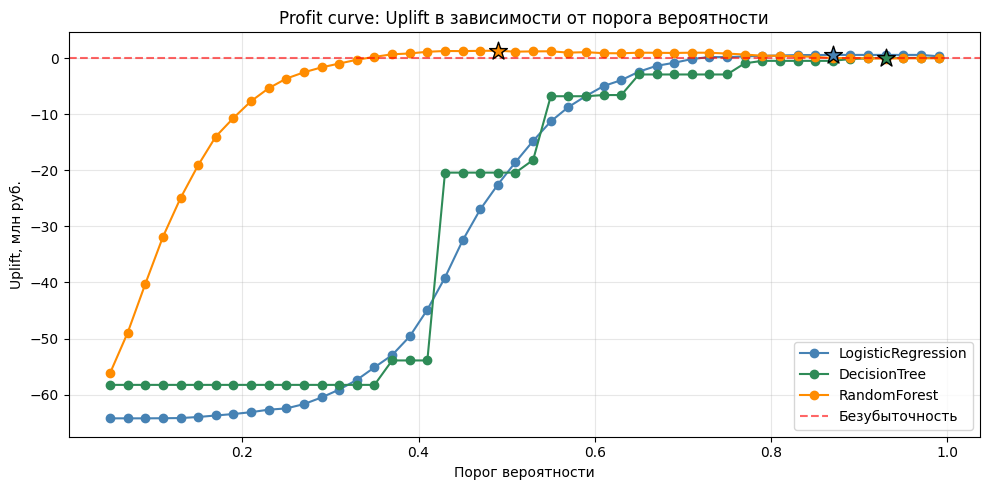

In [39]:
fig, ax = plt.subplots(figsize=(10, 5))

for df, name, color in [
    (logreg_thr, 'LogisticRegression', 'steelblue'),
    (tree_thr,   'DecisionTree',       'seagreen'),
    (rf_thr,     'RandomForest',       'darkorange'),
]:
    ax.plot(df['threshold'], df['Uplift_mln'], marker='o', label=name, color=color)
    best = find_best_threshold(df)
    ax.scatter(best['threshold'], best['Uplift_mln'],
               color=color, s=180, marker='*', zorder=5, edgecolor='black')

ax.axhline(0, color='red', linestyle='--', alpha=0.6, label='Безубыточность')
ax.set_title('Profit curve: Uplift в зависимости от порога вероятности')
ax.set_xlabel('Порог вероятности')
ax.set_ylabel('Uplift, млн руб.')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
def predict_at_threshold(model, X, threshold):
    """Предсказание с кастомным порогом вероятности."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def build_final_row(name, y_true, y_pred, threshold):
    """Строка финальной таблицы: метрики + бизнес-эффект + проверка порогов."""
    r = recall_score(y_true, y_pred, zero_division=0)
    p = precision_score(y_true, y_pred, zero_division=0)
    u = business_uplift(y_true, y_pred)
    return {
        'Модель':            name,
        'Опт. порог':        round(threshold, 2),
        'Recall':            round(r, 4),
        'Precision':         round(p, 4),
        'Uplift (млн ₽)':    round(u['uplift_rub'] / 1_000_000, 2),
        'Recall ≥ 0.50':     '✅' if r >= RECALL_MIN else '❌',
        'Precision ≥ 0.143': '✅' if p >= PRECISION_MIN else '❌',
        'Uplift > 0':        '✅' if u['uplift_rub'] > 0 else '❌',
    }


# Вытаскиваем оптимальные пороги из результатов threshold tuning
best_logreg = find_best_threshold(logreg_thr)
best_tree   = find_best_threshold(tree_thr)
best_rf_thr = find_best_threshold(rf_thr)

# Предсказания при оптимальных порогах
y_pred_logreg_opt = predict_at_threshold(logreg_pipeline, X_test, best_logreg['threshold'])
y_pred_tree_opt   = predict_at_threshold(tree_pipeline,   X_test, best_tree['threshold'])
y_pred_rf_opt     = predict_at_threshold(best_rf,         X_test, best_rf_thr['threshold'])

# Dummy остаётся при стандартном 0.5 (у него нет смысла в tuning)
final_results = pd.DataFrame([
    build_final_row('Dummy',                y_test, y_pred_dummy,      0.50),
    build_final_row('LogisticRegression',   y_test, y_pred_logreg_opt, best_logreg['threshold']),
    build_final_row('DecisionTree',         y_test, y_pred_tree_opt,   best_tree['threshold']),
    build_final_row('RandomForest (tuned)', y_test, y_pred_rf_opt,     best_rf_thr['threshold']),
])

print("=== Финальное сравнение: все модели при своих оптимальных порогах ===")
print(final_results.to_string(index=False))

=== Финальное сравнение: все модели при своих оптимальных порогах ===
              Модель  Опт. порог  Recall  Precision  Uplift (млн ₽) Recall ≥ 0.50 Precision ≥ 0.143 Uplift > 0
               Dummy        0.50    0.00       0.00            0.00             ❌                 ❌          ❌
  LogisticRegression        0.87    0.08       1.00            0.60             ❌                 ✅          ✅
        DecisionTree        0.93    0.01       1.00            0.06             ❌                 ✅          ✅
RandomForest (tuned)        0.49    0.47       0.22            1.35             ❌                 ✅          ✅


In [41]:
rf_fin = business_uplift(y_test, y_pred_rf_opt)

print(f"=== Финансовый отчёт RandomForest (threshold = {best_rf_thr['threshold']}) ===")
print(f"Поймано плохих (TP):        {rf_fin['TP']:>5}")
print(f"Ошибочно отклонено (FP):    {rf_fin['FP']:>5}")
print(f"Пропущено плохих (FN):      {rf_fin['FN']:>5}")
print(f"Сэкономлено на TP:          {rf_fin['saved_losses_rub']:>15,} ₽")
print(f"Потеряно на FP:             {rf_fin['lost_profit_rub']:>15,} ₽")
print(f"Упущенная прибыль на FN:    {rf_fin['missed_loss_rub']:>15,} ₽")
print(f"ИТОГО Uplift от baseline:   {rf_fin['uplift_rub']:>15,} ₽")

=== Финансовый отчёт RandomForest (threshold = 0.49) ===
Поймано плохих (TP):           57
Ошибочно отклонено (FP):      207
Пропущено плохих (FN):         65
Сэкономлено на TP:                3,420,000 ₽
Потеряно на FP:                   2,070,000 ₽
Упущенная прибыль на FN:          3,900,000 ₽
ИТОГО Uplift от baseline:         1,350,000 ₽


Вывод - мы видим, что Случайный лес позволяет получить нам намного большую выгоду, чем у простых моделей и мы почти перешли порог в 0.5 recall (0.47 получили, мы бы скорее всего получили 0.5, но потеряли бы в деньгах - а это бизнес не одобрит). И хотя пресижн не такой высокий как у простых моделей, но выше заданного порога - нас это устраивает

Случайный лес — единственная модель, экономически оправданная: Uplift = +1.35 млн ₽, Precision = 0.22 (проходит порог), Recall = 0.47 (на 3 п.п. ниже порога 0.50).

LogReg и Tree формально дают положительный Uplift (0.6 и 0.06 млн), но проваливают Recall (0.08 и 0.01) — они отклоняют почти всех подряд, ловя малую долю плохих. Такая модель бесполезна: банк отклоняет в 10 раз больше хороших, чем ловит плохих.

RF обходит бейзлайн по Uplift в 2.25 раза — мы это ожидали от более сложной модели

3.1 Получена глобальная интерпретация построенной модели, включая визуализации

/tmp/ipykernel_4501/2064344604.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x='importance', y='feature', palette='viridis')


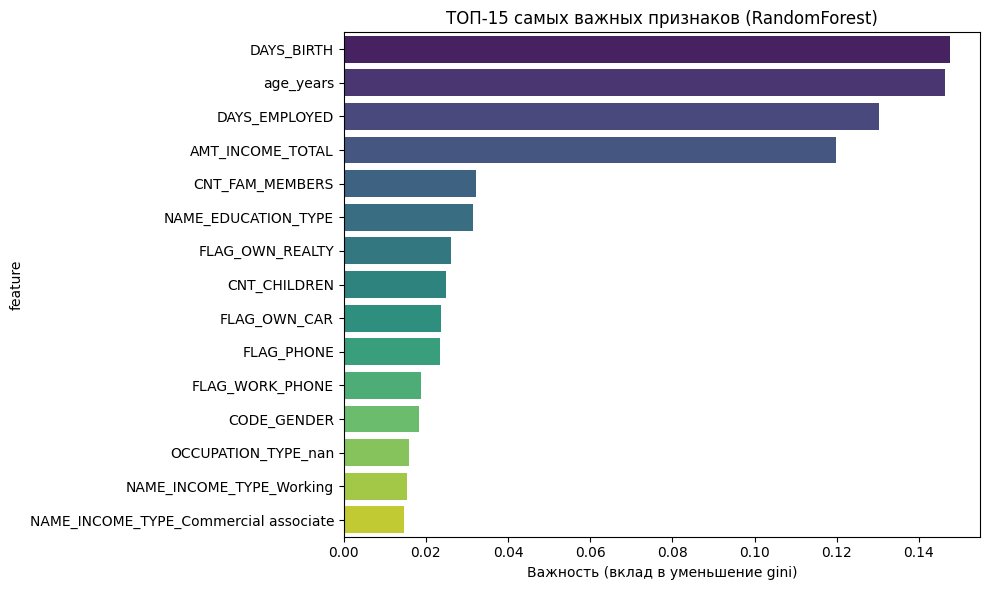

ТОП-5:
         feature  importance
      DAYS_BIRTH        0.15
       age_years        0.15
   DAYS_EMPLOYED        0.13
AMT_INCOME_TOTAL        0.12
 CNT_FAM_MEMBERS        0.03


In [42]:
cat_encoder = best_rf.named_steps['preprocessor'].named_transformers_['cat']
feature_names = (
    numeric_features
    + list(cat_encoder.get_feature_names_out(categorical_features))
)

importances = best_rf.named_steps['classifier'].feature_importances_

importance_df = (
    pd.DataFrame({'feature': feature_names, 'importance': importances})
    .sort_values('importance', ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance_df, x='importance', y='feature', palette='viridis')
plt.title('ТОП-15 самых важных признаков (RandomForest)')
plt.xlabel('Важность (вклад в уменьшение gini)')
plt.tight_layout()
plt.show()

print("ТОП-5:")
print(importance_df.head(5).to_string(index=False))

На данном моменте понял, что надо было убрать два фактора, которые задваиваются и показывают возврат клиента

Наибольшее влияние имеют факторы: возраст, количество дней работы - стаж, доход - логичные факторы платежеспособности клиента. Значит модель логично и намного лучше чувствует закономерность по сравнению с бейзлайнами

Проверяем логику модели на "плохом" и "хорошем" клиенте - как она их делит

In [43]:
# ---- 0. Устанавливаем и импортируем shap (если ещё не сделано) ----
try:
    import shap
except ImportError:
    !pip install shap -q
    import shap

import numpy as np
import pandas as pd


# ---- 1. Находим по одному правильно предсказанному клиенту ----
y_test_array = np.asarray(y_test)
correct_good = np.where((y_test_array == 0) & (y_pred_rf_opt == 0))[0][0]
correct_bad  = np.where((y_test_array == 1) & (y_pred_rf_opt == 1))[0][0]

# ---- 2. Трансформируем только 2 строки ----
X_two = X_test.iloc[[correct_good, correct_bad]]
X_two_transformed = best_rf.named_steps['preprocessor'].transform(X_two)

# ---- 3. Вероятности ----
probas = best_rf.predict_proba(X_two)[:, 1]
proba_good, proba_bad = probas[0], probas[1]
threshold_opt = best_rf_thr['threshold']

# ---- 4. SHAP для 2 строк ----
explainer = shap.TreeExplainer(best_rf.named_steps['classifier'])
sv = explainer.shap_values(X_two_transformed)

# Нормализация формата SHAP (старый/новый)
if isinstance(sv, list):
    sv_class1 = sv[1]
elif sv.ndim == 3:
    sv_class1 = sv[:, :, 1]
else:
    sv_class1 = sv

# ---- 5. Функция для печати разбора ----
def print_client_analysis(label, idx, y_true, proba, sv_values):
    contrib = (
        pd.DataFrame({
            'feature':    feature_names,
            'value':      X_two_transformed[idx],
            'shap_value': sv_values[idx],
        })
        .assign(abs_shap=lambda d: d['shap_value'].abs())
        .sort_values('abs_shap', ascending=False)
        .head(5)
        [['feature', 'value', 'shap_value']]
    )
    direction = 'к ПЛОХОМУ (+)' if proba >= threshold_opt else 'к ХОРОШЕМУ (−)'
    decision = 'ОТКЛОНИТЬ' if proba >= threshold_opt else 'ОДОБРИТЬ'

    print("=" * 70)
    print(f"{label}  |  y_true={y_true}  |  P(плохой)={proba:.4f}  |  t={threshold_opt:.2f}")
    print(f"Решение модели: {decision}")
    print("=" * 70)
    print(f"{'Признак':<32}{'Значение':>12}{'SHAP':>12}{'Направление':>16}")
    print("-" * 70)
    for _, row in contrib.iterrows():
        sign = '+' if row['shap_value'] > 0 else '−'
        effect = 'плохой' if row['shap_value'] > 0 else 'хороший'
        print(f"{row['feature']:<32}{row['value']:>12.3f}"
              f"{row['shap_value']:>+12.4f}    {sign} → {effect:>8}")
    print()


# ---- 6. Печатаем оба клиента ----
print_client_analysis('ХОРОШИЙ КЛИЕНТ', idx=0, y_true=0,
                      proba=proba_good, sv_values=sv_class1)
print_client_analysis('ПЛОХОЙ КЛИЕНТ',  idx=1, y_true=1,
                      proba=proba_bad,  sv_values=sv_class1)

# ---- 7. Итоговая проверка логики ----
print("=" * 70)
print("ПРОВЕРКА ЛОГИКИ МОДЕЛИ")
print("=" * 70)
good_ok = proba_good < threshold_opt
bad_ok  = proba_bad  >= threshold_opt
print(f"Хороший клиент правильно одобрен (P < t)?       {good_ok}")
print(f"Плохой клиент правильно отклонён (P ≥ t)?       {bad_ok}")
print(f"Итог: логика модели работает корректно          {good_ok and bad_ok}")

ХОРОШИЙ КЛИЕНТ  |  y_true=0  |  P(плохой)=0.1676  |  t=0.49
Решение модели: ОДОБРИТЬ
Признак                             Значение        SHAP     Направление
----------------------------------------------------------------------
DAYS_EMPLOYED                         -0.448     -0.0578    − →  хороший
DAYS_BIRTH                             0.111     -0.0525    − →  хороший
age_years                             -0.111     -0.0504    − →  хороший
FLAG_OWN_CAR                           1.275     -0.0325    − →  хороший
CNT_CHILDREN                           0.764     -0.0260    − →  хороший

ПЛОХОЙ КЛИЕНТ  |  y_true=1  |  P(плохой)=0.5793  |  t=0.49
Решение модели: ОТКЛОНИТЬ
Признак                             Значение        SHAP     Направление
----------------------------------------------------------------------
DAYS_EMPLOYED                         -0.435     +0.0433    + →   плохой
NAME_FAMILY_STATUS_Single / not married       1.000     +0.0382    + →   плохой
CODE_GENDER            

Видим, что модель по пороговому значению определяет плохого и хорошего клиентов с учетом факторов. Дальше посмотрим визуализацию, как наши модели делят "Хороших" и "Плохих"

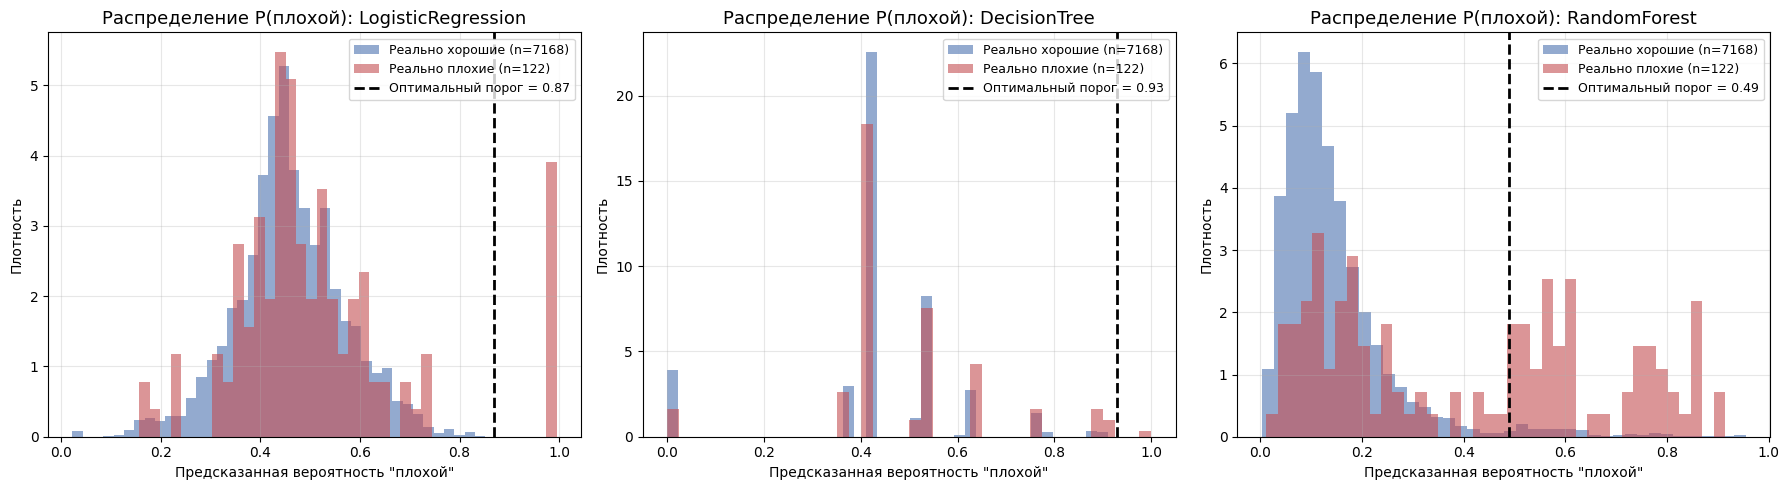

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, pipeline, name, thr, color_good, color_bad in [
    (axes[0], logreg_pipeline, 'LogisticRegression',
     best_logreg['threshold'],  '#4C72B0', '#C44E52'),
    (axes[1], tree_pipeline,   'DecisionTree',
     best_tree['threshold'],    '#4C72B0', '#C44E52'),
    (axes[2], best_rf,         'RandomForest',
     best_rf_thr['threshold'],  '#4C72B0', '#C44E52'),
]:
    proba = pipeline.predict_proba(X_test)[:, 1]
    y_arr = np.asarray(y_test)

    ax.hist(proba[y_arr == 0], bins=40, alpha=0.6,
            label=f'Реально хорошие (n={int((y_arr == 0).sum())})',
            color=color_good, density=True)
    ax.hist(proba[y_arr == 1], bins=40, alpha=0.6,
            label=f'Реально плохие (n={int((y_arr == 1).sum())})',
            color=color_bad, density=True)

    ax.axvline(thr, color='black', linestyle='--', linewidth=2,
               label=f'Оптимальный порог = {thr:.2f}')

    ax.set_title(f'Распределение P(плохой): {name}', fontsize=13)
    ax.set_xlabel('Предсказанная вероятность "плохой"')
    ax.set_ylabel('Плотность')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

На графиках видим, что Случайный лес намного лучше делает классификацию клиентов - больше "плохих" отделяет правильно, а простые модели только самых очевидных проблемных клиентов находит

In [45]:
# Единый список имён признаков после предобработки
prep_feature_names = [
    n.split('__', 1)[1] if '__' in n else n
    for n in best_rf.named_steps['preprocessor'].get_feature_names_out()
]

logreg_model = logreg_pipeline.named_steps['classifier']
coefs = logreg_model.coef_[0]
intercept = logreg_model.intercept_[0]

coef_df = (
    pd.DataFrame({
        'feature':     prep_feature_names,
        'coefficient': coefs,
        'abs_coef':    np.abs(coefs),
    })
    .sort_values('abs_coef', ascending=False)
)

print(f"Сдвиг b₀: {intercept:.4f} | Всего коэффициентов: {len(coef_df)}")
print(f"\nТОП-15 по |коэффициенту|:")
print(coef_df.head(15).to_string(index=False))

print("\nТОП-5 → 'ПЛОХОМУ' (+коэффициент):")
print(coef_df[coef_df['coefficient'] > 0].head(5).to_string(index=False))

print("\nТОП-5 → 'ХОРОШЕМУ' (−коэффициент):")
print(coef_df[coef_df['coefficient'] < 0].head(5).to_string(index=False))

Сдвиг b₀: 1.4274 | Всего коэффициентов: 51

ТОП-15 по |коэффициенту|:
                                feature  coefficient  abs_coef
                            is_employed         6.36      6.36
                          DAYS_EMPLOYED         4.89      4.89
             NAME_INCOME_TYPE_Pensioner         3.67      3.67
      NAME_FAMILY_STATUS_Civil marriage        -3.10      3.10
          OCCUPATION_TYPE_Realty agents        -3.06      3.06
             NAME_FAMILY_STATUS_Married        -2.98      2.98
               NAME_FAMILY_STATUS_Widow         2.71      2.71
           NAME_FAMILY_STATUS_Separated         1.91      1.91
NAME_FAMILY_STATUS_Single / not married         1.81      1.81
                       adults_in_family         1.81      1.81
               OCCUPATION_TYPE_IT staff         1.60      1.60
               NAME_INCOME_TYPE_Student        -1.25      1.25
  OCCUPATION_TYPE_Private service staff        -1.16      1.16
     NAME_HOUSING_TYPE_Office apartment         

Коэффициенты LogisticRegression

Модель обучена на стандартизированных признаках, поэтому коэффициенты сравнимы по модулю. Знак показывает направление: положительный коэффициент толкает к классу «плохой», отрицательный — к «хорошему». Всего 51 коэффициент + сдвиг b₀ = 1.426.

Топ-5 признаков, повышающих риск дефолта:

is_employed (+6.40) — самый сильный фактор;

DAYS_EMPLOYED (+4.92);

NAME_INCOME_TYPE_Pensioner (+3.67) — согласуется с EDA: по гистограммам из HW1 пенсионеры действительно имеют самую высокую долю «плохих»;

NAME_FAMILY_STATUS_Widow (+2.69) и NAME_FAMILY_STATUS_Separated (+1.90) — одиночное домохозяйство, ниже платёжеспособность.

In [46]:
from sklearn.tree import export_text, plot_tree

tree_model = tree_pipeline.named_steps['classifier']

print(f"DecisionTree: глубина={tree_model.get_depth()}, "
      f"листьев={tree_model.get_n_leaves()}, узлов={tree_model.tree_.node_count}")

rules = export_text(
    tree_model,
    feature_names=prep_feature_names,
    decimals=2,
    max_depth=3,
)
print(f"\nПравила (первые 3 уровня):")
print(rules)

DecisionTree: глубина=5, листьев=25, узлов=49

Правила (первые 3 уровня):
|--- DAYS_EMPLOYED <= -0.44
|   |--- age_years <= 1.04
|   |   |--- DAYS_BIRTH <= -0.69
|   |   |   |--- DAYS_EMPLOYED <= -0.46
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- DAYS_EMPLOYED >  -0.46
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- DAYS_BIRTH >  -0.69
|   |   |   |--- NAME_INCOME_TYPE_Pensioner <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- NAME_INCOME_TYPE_Pensioner >  0.50
|   |   |   |   |--- class: 1
|   |--- age_years >  1.04
|   |   |--- OCCUPATION_TYPE_nan <= 0.50
|   |   |   |--- CNT_CHILDREN <= 0.09
|   |   |   |   |--- class: 0
|   |   |   |--- CNT_CHILDREN >  0.09
|   |   |   |   |--- class: 0
|   |   |--- OCCUPATION_TYPE_nan >  0.50
|   |   |   |--- AMT_INCOME_TOTAL <= -0.18
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- AMT_INCOME_TOTAL >  -0.18
|   |   |   |   |--- class: 0
|--- DAYS_EMPLOYED >  -0.44
|   |-

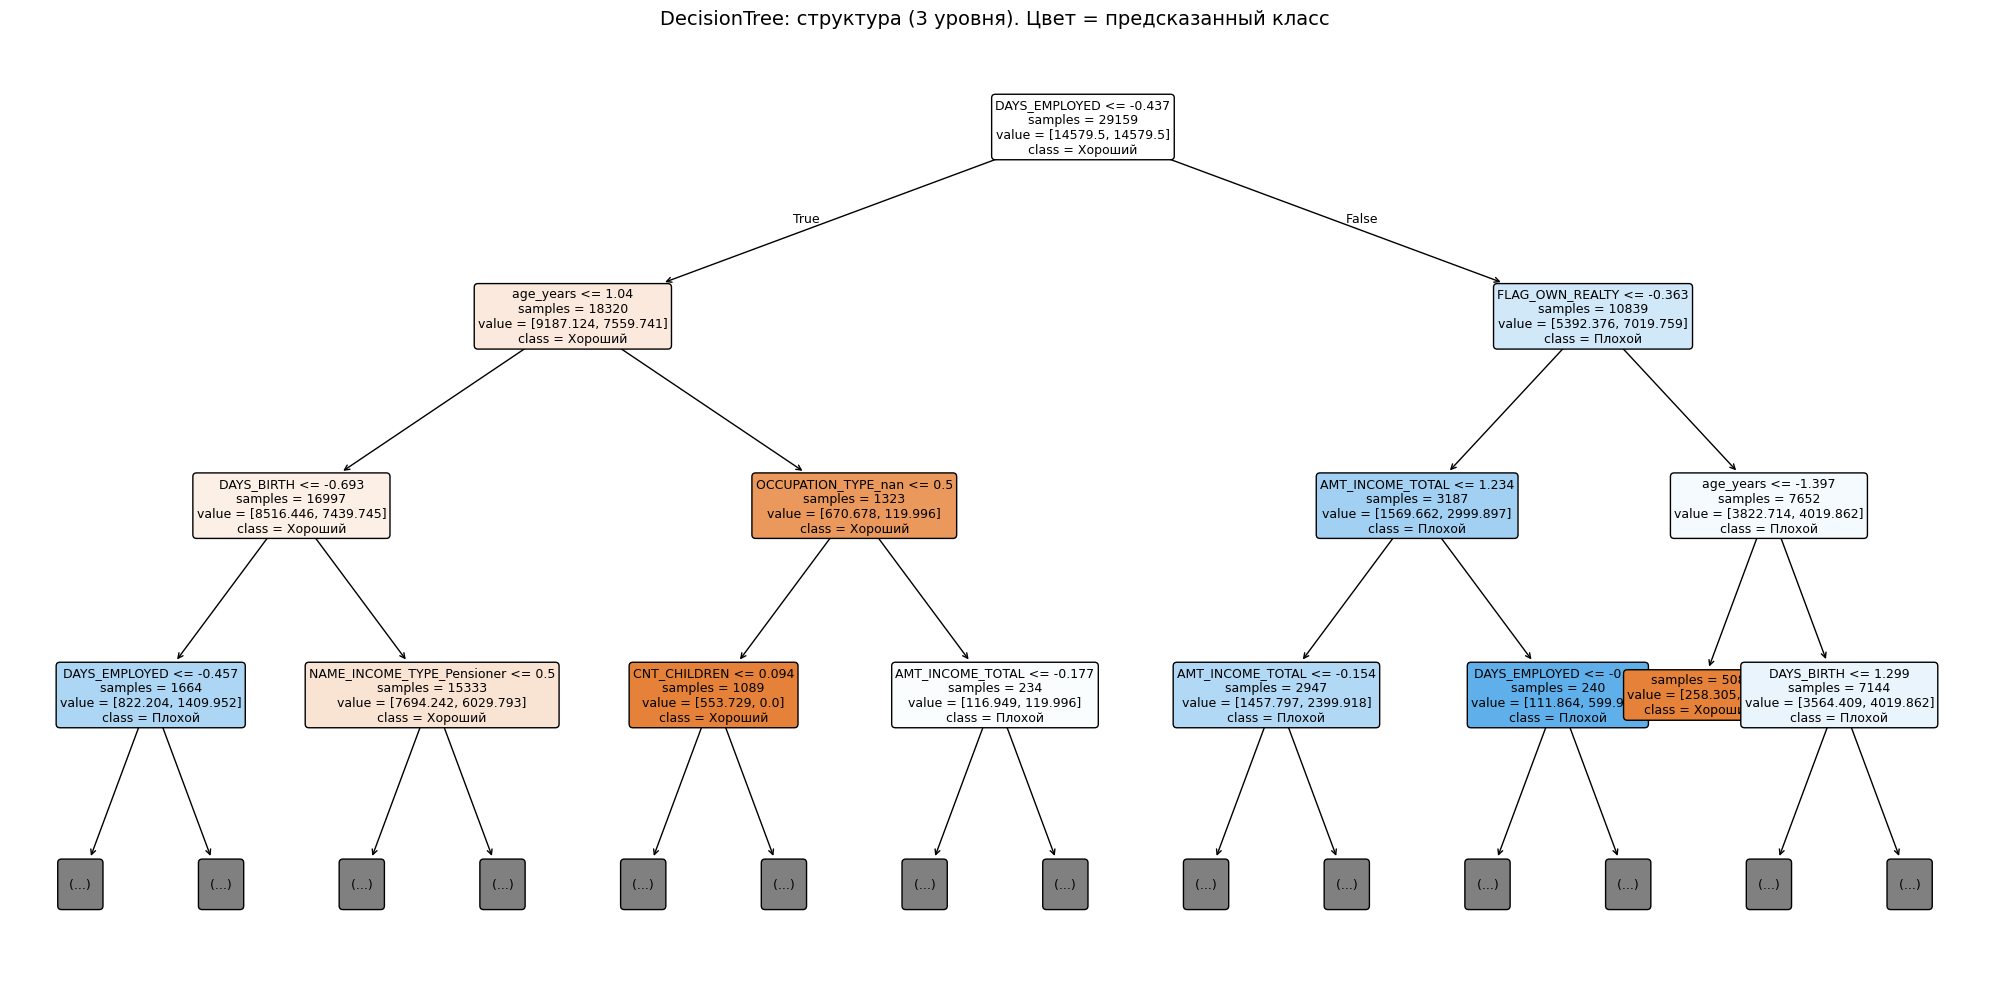

In [47]:
# Визуализация структуры дерева
plt.figure(figsize=(20, 10))
plot_tree(
    tree_model,
    feature_names=prep_feature_names,
    class_names=['Хороший', 'Плохой'],
    filled=True, rounded=True,
    max_depth=3, fontsize=9,
    impurity=False,
)
plt.title('DecisionTree: структура (3 уровня). Цвет = предсказанный класс', fontsize=14)
plt.tight_layout()
plt.show()

Правила DecisionTree

Модель — дерево глубины 5 с 25 листьями (49 узлов). Каждый путь от корня до листа — правило «если → то». Финальный класс в листе (class: 0 или class: 1) — предсказание для всех клиентов, попавших в этот лист.

Логика верхних уровней дерева:

Первый (главный) раскол — DAYS_EMPLOYED <= -0.44: модель разделяет клиентов по стабильности занятости. Это самый информативный признак, согласуется с feature_importances_ RandomForest.

Второй уровень — age_years и FLAG_OWN_REALTY: возраст и наличие имущества. Классические факторы платёжеспособности.

Третий уровень — NAME_INCOME_TYPE_Pensioner, CNT_CHILDREN, AMT_INCOME_TOTAL: доход и состав семьи.

In [48]:
rf_model = best_rf.named_steps['classifier']
tree_example = rf_model.estimators_[0]

print(f"RandomForest: {len(rf_model.estimators_)} деревьев")
print(f"Дерево №0: глубина={tree_example.get_depth()}, "
      f"листьев={tree_example.get_n_leaves()}, узлов={tree_example.tree_.node_count}")

rules_rf = export_text(
    tree_example,
    feature_names=prep_feature_names,
    decimals=2,
    max_depth=2,
)
print(f"\nПервые 2 уровня дерева №0:")
print(rules_rf)

RandomForest: 100 деревьев
Дерево №0: глубина=20, листьев=523, узлов=1045

Первые 2 уровня дерева №0:
|--- OCCUPATION_TYPE_High skill tech staff <= 0.50
|   |--- FLAG_OWN_REALTY <= -0.36
|   |   |--- DAYS_EMPLOYED <= -0.44
|   |   |   |--- truncated branch of depth 18
|   |   |--- DAYS_EMPLOYED >  -0.44
|   |   |   |--- truncated branch of depth 17
|   |--- FLAG_OWN_REALTY >  -0.36
|   |   |--- FLAG_OWN_CAR <= 0.25
|   |   |   |--- truncated branch of depth 18
|   |   |--- FLAG_OWN_CAR >  0.25
|   |   |   |--- truncated branch of depth 18
|--- OCCUPATION_TYPE_High skill tech staff >  0.50
|   |--- NAME_INCOME_TYPE_State servant <= 0.50
|   |   |--- DAYS_EMPLOYED <= -0.47
|   |   |   |--- class: 0.0
|   |   |--- DAYS_EMPLOYED >  -0.47
|   |   |   |--- truncated branch of depth 12
|   |--- NAME_INCOME_TYPE_State servant >  0.50
|   |   |--- NAME_EDUCATION_TYPE <= 1.03
|   |   |   |--- truncated branch of depth 2
|   |   |--- NAME_EDUCATION_TYPE >  1.03
|   |   |   |--- truncated branch o

Одно дерево из RandomForest

Лес состоит из 100 деревьев, но каждое обучено на случайной подвыборке данных и случайном подмножестве признаков. Дерево №0 имеет глубину 20, 523 листа, 1045 узлов — в разы сложнее одиночного бейзлайна (глубина 5).

Логика верхних уровней дерева №0:

Первый раскол — OCCUPATION_TYPE_High skill tech staff: модель выделяет IT-специалистов и инженеров как отдельную группу.

Второй уровень — FLAG_OWN_REALTY, NAME_INCOME_TYPE_State servant, NAME_EDUCATION_TYPE: имущество, тип занятости, образование.

# ВЫВОД ПО ИТОГОВОЙ МОДЕЛИ

1. Адекватность признаков. Модель Случайный лес опирается на классические факторы кредитного скоринга — возраст, доход, стаж на текущем месте, факт занятости. Это полностью соответствует практике риск-менеджмента банков. В топ-5 важных признаков нет технических флагов (FLAG_MOBIL например), что подтверждает: модель выявила содержательные закономерности, а не подогналась под шум

2. Решения на уровне отдельного клиента. SHAP-объяснения демонстрируют логичную картину: для определения клиента важен стабильный доход, длительный стаж, наличие имущества. Модель даёт объяснимые предсказания, что важно для объяснения регулятору. Клиенту можно аргументированно объяснить причину отказа

3. Бизнес-ценность. RandomForest продемонстрировал принципиальное преимущество над бейзлайнами

LogReg и одиночное дерево формально дают положительный uplift, но при Recall 0.08 и 0.01 — они отклоняют почти всех подряд, и находят очень мало "Плохих клиентов". Такая модель бесполезна: банк теряет лояльных клиентов, не решая задачу защиты от рисков

Случайный лес при пороге 0.49 даёт Uplift = + 1.35 млн.руб (в 2.25 раза выше лучшего бейзлайна), Precision = 0.22 (уверенно выше экономического порога 0.143), Recall = 0.47 — практически достигает целевого уровня 0.50

Проверка экономического порога: из 100 отклонённых клиентов 22 реально плохих, что даёт чистый плюс +540 000 ₽ на каждые 100 отказов

4. Ограничения и рекомендация. Несмотря на успешный результат, важно честно обозначить границы применимости

Recall 0.47 не дотягивает до целевого 0.50. При пороге ~0.44 модель достигнет Recall = 0.50, но Uplift снизится до ~1.0 млн ₽ (банк платит ~350 тыс. ₽ за повышение отлова дефолтников с 47% до 50%).

Модель пригодна для пилотного внедрения, как дополнительный фильтр к уже существующему скорингу, но пока не как самостоятельный инструмент принятия решения - требуется проверка

Для достижения target-метрик банка (Recall ≥ 0.5, Precision ≥ 0.15 при Uplift ≥ 2 млн ₽) возможно будут полезны дополнительные данные - кредитная история, транзакции по дебетовой карте, использование мобильного приложения

Итоговый вердикт: модель демонстрирует реальный потенциал - в отличие от бейзлайнов, RandomForest нашел экономически осмысленную точку принятия решений. Мы получили работающий скоринг готовый к проверке в реальности (в дополнение к уже существующему скорингу)